# 03 · Skill categories: one group per skill

This notebook gives every skill in `vacancy_skills` a **group** (Languages, Soft skills, Technical / IT, ...) and a **subgroup**. It uses the ESCO files in `data/reference/esco/` and your corrections in `data/reference/skill_category_overrides.csv`.

The result is a small lookup table, `data/processed/skill_categories.parquet`, with **one row per skill**. Notebooks 04 and 05 join it to `vacancy_skills` on `skill_uri`. It uses the tables from `02_clean_data.ipynb`.

## How it works

1. Join the skills in the data to ESCO `skills_en` on `skill_uri`.
2. A few old skills are no longer in ESCO v1.2.1. They are matched by name, first on the preferred name and then on alternative names.
3. Look up each skill in the ESCO lists (language, transversal, digital) and walk up the ESCO hierarchy to find its subgroup.
4. Apply the group rules below, in this order. The first rule that fits wins.
5. Apply your overrides. **Your corrections always win.**

| Order | Rule | Group |
|---|---|---|
| 1 | in the ESCO language list | Languages |
| 2 | in the digital list and under "working with computers" | Basic digital |
| 3 | in the digital list, anything else | Technical / IT |
| 4 | in the transversal list, or reuse level "transversal" | Soft skills |
| 5 | ESCO type "knowledge" | Knowledge |
| 6 | everything else | Job-specific skills |

Nothing in the data is changed. Run the cells from top to bottom.

## 0. Settings and loading

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)

# The allowed groups. Overrides must use one of these names exactly.
GROUPS = ['Languages', 'Soft skills', 'Basic digital', 'Technical / IT',
          'Knowledge', 'Job-specific skills']

# Number of most-mentioned skills saved in the review file.
N_REVIEW = 150

# Support running from either the project root or notebooks/.
project_dir = Path.cwd()
if not (project_dir / 'data' / 'processed').is_dir():
    project_dir = project_dir.parent
processed_dir = project_dir / 'data' / 'processed'
reference_dir = project_dir / 'data' / 'reference'
esco_dir = reference_dir / 'esco'
overrides_path = reference_dir / 'skill_category_overrides.csv'
output_dir = project_dir / 'outputs' / '03_skill_categories'
output_dir.mkdir(parents=True, exist_ok=True)

def load_table(name):
    parquet = processed_dir / f'{name}.parquet'
    if parquet.exists():
        return pd.read_parquet(parquet)
    return pd.read_csv(processed_dir / f'{name}.csv.gz')

vacancies = load_table('vacancies')
vacancy_skills = load_table('vacancy_skills')
print('vacancies:', f'{len(vacancies):,}', 'rows')
print('vacancy_skills:', f'{len(vacancy_skills):,}', 'rows')

vacancies: 332,526 rows
vacancy_skills: 2,731,194 rows


### ESCO files

- `skills_en`: one row per ESCO skill, with its type (skill or knowledge), reuse level and names. A few skills appear twice, so duplicates are dropped.
- The three lists: language, transversal and digital skills.
- `skillsHierarchy_en`: the top levels of the ESCO tree (level 0 to level 3).
- `broaderRelationsSkillPillar_en`: the parent of each skill. It links each skill up to the hierarchy.

In [2]:
def read_esco(name):
    return pd.read_csv(esco_dir / f'{name}.csv', dtype=str)

esco = read_esco('skills_en')
print('skills_en rows:', f'{len(esco):,}', '| duplicate skills dropped:', esco['conceptUri'].duplicated().sum())
esco = esco.drop_duplicates('conceptUri').set_index('conceptUri')

language_list = set(read_esco('languageSkillsCollection_en')['conceptUri'])
transversal_list = set(read_esco('transversalSkillsCollection_en')['conceptUri'])
digital_list = set(read_esco('digitalSkillsCollection_en')['conceptUri'])
hierarchy = read_esco('skillsHierarchy_en')
broader = read_esco('broaderRelationsSkillPillar_en')

print('language list:', len(language_list), '| transversal list:', len(transversal_list),
      '| digital list:', len(digital_list))
print('hierarchy rows:', len(hierarchy), '| broader relations:', f'{len(broader):,}')

skills_en rows: 13,960 | duplicate skills dropped: 21
language list: 359 | transversal list: 95 | digital list: 1284
hierarchy rows: 640 | broader relations: 20,819


## 1. One row per skill

Count how often each skill appears: `mentions` is the number of vacancy–skill rows, `vacancies` the number of different vacancies.

In [3]:
skills = (vacancy_skills
          .groupby('skill_uri', observed=True)
          .agg(skill=('skill', 'first'),
               mentions=('vacancy_key', 'size'),
               vacancies=('vacancy_key', 'nunique'))
          .reset_index())
skills['skill_uri'] = skills['skill_uri'].astype(str)
skills['skill'] = skills['skill'].astype(str)
skills = skills.sort_values('mentions', ascending=False, ignore_index=True)
print('distinct skills:', f'{len(skills):,}')
display(skills.head(10))

distinct skills: 4,640


,skill_uri,skill,mentions,vacancies
0,http://data.europa.eu/esco/skill/15d76317-c71a-4fa2-aadc...,communication,92743,92743
1,http://data.europa.eu/esco/skill/6d3edede-8951-4621-a835...,English,90509,90509
2,http://data.europa.eu/esco/skill/f683ae1d-cb7c-4aa1-b9fe...,use microsoft office,86344,86344
3,http://data.europa.eu/esco/skill/cffc3e97-e942-4b13-a2f3...,use technical documentation,66640,66640
4,http://data.europa.eu/esco/skill/e747e77e-0ea1-4001-8b07...,French,64897,64897
5,http://data.europa.eu/esco/skill/a941f0e5-e015-4249-aaa4...,cooperate with professionals,64392,64392
6,http://data.europa.eu/esco/skill/ddc3119d-1d6e-4324-9125...,computer technology,61501,61501
7,http://data.europa.eu/esco/skill/60c78287-22eb-4103-9c8c...,work in teams,54345,54345
8,http://data.europa.eu/esco/skill/c29aa9d2-4da8-4bdd-831c...,work independently,53887,53887
9,http://data.europa.eu/esco/skill/4812a4ea-dc55-4dc6-b9b0...,German,49645,49645


## 2. Join to ESCO

Most skills are found directly by `skill_uri`. The data covers 2015–2026 and ESCO has changed since then, so a few old URIs are no longer in ESCO v1.2.1. For those:

1. look for exactly one ESCO skill with the same **preferred name**;
2. otherwise look for exactly one ESCO skill with the same **alternative name**;
3. otherwise leave the skill unmatched. These are placed by hand in the overrides file.

The name comparison ignores upper and lower case.

In [4]:
by_name = {}
for uri, label in esco['preferredLabel'].items():
    by_name.setdefault(str(label).strip().lower(), set()).add(uri)

by_alt_name = {}
for uri, labels in esco['altLabels'].dropna().items():
    for label in labels.split('\n'):
        if label.strip():
            by_alt_name.setdefault(label.strip().lower(), set()).add(uri)

def match_skill(uri, name):
    if uri in esco.index:
        return uri, 'uri'
    key = name.strip().lower()
    found = by_name.get(key, set())
    if len(found) == 1:
        return next(iter(found)), 'preferred name'
    found_alt = by_alt_name.get(key, set())
    if len(found) == 0 and len(found_alt) == 1:
        return next(iter(found_alt)), 'alternative name'
    if len(found) > 1 or len(found_alt) > 1:
        return None, 'ambiguous name'
    return None, 'no match'

matched = [match_skill(u, s) for u, s in zip(skills['skill_uri'], skills['skill'])]
skills['esco_uri'] = [m[0] for m in matched]
skills['matched_how'] = [m[1] for m in matched]

match_summary = (skills.groupby('matched_how')
                 .agg(skills=('skill_uri', 'size'), mentions=('mentions', 'sum'))
                 .sort_values('mentions', ascending=False))
match_summary['% of mentions'] = (100 * match_summary['mentions'] / skills['mentions'].sum()).round(2)
display(match_summary)

print('Old skills matched by name:')
display(skills[skills['matched_how'].isin(['preferred name', 'alternative name'])]
        .assign(esco_name=lambda d: d['esco_uri'].map(esco['preferredLabel']))
        [['skill', 'esco_name', 'matched_how', 'mentions']].head(15))
print('Old skills not matched (they need an override):')
display(skills[skills['esco_uri'].isna()][['skill', 'matched_how', 'mentions', 'skill_uri']])

,skills,mentions,% of mentions
matched_how,,,
uri,4585,2701522,98.91
alternative name,40,26933,0.99
no match,10,2503,0.09
preferred name,4,235,0.01
ambiguous name,1,1,0.00


Old skills matched by name:


,skill,esco_name,matched_how,mentions
30,conduct cleaning tasks,perform cleaning duties,alternative name,15203
121,alter management,apply change management,alternative name,3614
144,ensure customer orientation,ensure client orientation,alternative name,3091
271,manage personnel,manage staff,alternative name,1482
440,materials science,materials engineering,alternative name,761
486,take payments for bills,process payments,alternative name,652
624,prepare ground for construction,prepare building site,alternative name,416
667,execute administration,perform clerical duties,alternative name,380
683,dispose waste,manage waste,alternative name,360
875,manage cash flow,handle cash flow,alternative name,220


Old skills not matched (they need an override):


,skill,matched_how,mentions,skill_uri
194,manage work,no match,2169,http://data.europa.eu/esco/skill/56a2fa94-a66d-40c6-a444...
1046,develop an organisational structure,no match,154,http://data.europa.eu/esco/skill/8538c0e3-902f-4e6f-a60c...
1104,Windows Phone,no match,138,http://data.europa.eu/esco/skill/968ea96d-42d0-44fe-94b0...
2302,manage operational budgets,no match,16,http://data.europa.eu/esco/skill/51b53bb3-7a67-4ce8-b959...
2757,acting and directing techniques,no match,9,http://data.europa.eu/esco/skill/91fc256e-00ec-4367-b3b4...
2907,SaaS (service-oriented modelling),no match,7,http://data.europa.eu/esco/skill/eeca3780-8049-499f-a268...
3211,create working methodology,no match,5,http://data.europa.eu/esco/skill/c3f8aaaa-7010-4e51-8b19...
3570,set hygiene standards,no match,3,http://data.europa.eu/esco/skill/202c0a90-e45f-4b9a-8bd2...
4472,install sprinkler systems,no match,1,http://data.europa.eu/esco/skill/687c2470-c2bb-4891-a643...
4579,budget set costs,ambiguous name,1,http://data.europa.eu/esco/skill/1972c7f5-b157-42ad-bd7e...


## 3. ESCO details for each skill

For each matched skill, collect:

- `esco_skill_type`: "skill/competence" or "knowledge"
- `reuse_level`: transversal, cross-sector, sector-specific or occupation-specific
- whether it is in the language, transversal or digital list
- its **paths** up the ESCO tree. A skill can have several parents, so it can have several paths. For example, a skill can sit both under "skills" and under "knowledge".

In [5]:
# Where each hierarchy concept sits: (level 0 term, level 1 term, level 2 term).
position = {}
for _, row in hierarchy.iterrows():
    for level in [3, 2, 1, 0]:
        uri = row[f'Level {level} URI']
        if isinstance(uri, str) and uri not in position:
            position[uri] = (row['Level 0 preferred term'],
                             row['Level 1 preferred term'] if level >= 1 else None,
                             row['Level 2 preferred term'] if level >= 2 else None)

parents = broader.groupby('conceptUri')['broaderUri'].apply(list).to_dict()

def paths_up(uri, seen=None):
    # Walk up the parents until reaching a concept in the hierarchy file.
    seen = set() if seen is None else seen
    if uri in position:
        return {position[uri]}
    found = set()
    for parent in parents.get(uri, []):
        if parent not in seen:
            seen.add(parent)
            found |= paths_up(parent, seen)
    return found

m = skills['esco_uri']
skills['esco_name'] = m.map(esco['preferredLabel'])
skills['esco_skill_type'] = m.map(esco['skillType'])
skills['reuse_level'] = m.map(esco['reuseLevel'])
skills['in_language_list'] = m.isin(language_list)
skills['in_transversal_list'] = m.isin(transversal_list)
skills['in_digital_list'] = m.isin(digital_list)
skills['paths'] = [sorted(paths_up(u), key=str) if isinstance(u, str) else [] for u in m]
skills['level1_terms'] = skills['paths'].map(lambda p: sorted({x[1] for x in p if x[1]}))

n_top = skills['paths'].map(lambda p: len({x[0] for x in p}))
print('skills with no path:', (skills['esco_uri'].notna() & (n_top == 0)).sum())
print('share of mentions with paths in more than one top level:',
      f"{100 * skills.loc[n_top > 1, 'mentions'].sum() / skills['mentions'].sum():.1f}%")
display(skills[['skill', 'esco_skill_type', 'reuse_level', 'in_language_list',
                'in_transversal_list', 'in_digital_list', 'level1_terms']].head(10))

skills with no path: 0
share of mentions with paths in more than one top level: 22.0%


,skill,esco_skill_type,reuse_level,in_language_list,in_transversal_list,in_digital_list,level1_terms
0,communication,knowledge,cross-sector,False,False,False,[generic programmes and qualifications]
1,English,knowledge,transversal,True,False,False,"[core skills and competences, languages]"
2,use microsoft office,skill/competence,cross-sector,False,False,True,[working with computers]
3,use technical documentation,skill/competence,cross-sector,False,False,False,[information skills]
4,French,knowledge,transversal,True,False,False,"[core skills and competences, languages]"
5,cooperate with professionals,skill/competence,sector-specific,False,False,False,"[communication, collaboration and creativity]"
6,computer technology,knowledge,cross-sector,False,False,True,"[engineering, manufacturing and construction]"
7,work in teams,skill/competence,transversal,False,True,False,[social and communication skills and competences]
8,work independently,skill/competence,transversal,False,True,False,[self-management skills and competences]
9,German,knowledge,transversal,True,False,False,"[core skills and competences, languages]"


## 4. Group rules

The rules from the table at the top, in order. Unmatched skills get "Unmatched" for now.

In [6]:
def rule_group(row):
    if pd.isna(row['esco_uri']):
        return 'Unmatched'
    if row['in_language_list']:
        return 'Languages'
    if row['in_digital_list']:
        if 'working with computers' in row['level1_terms']:
            return 'Basic digital'
        return 'Technical / IT'
    if row['in_transversal_list'] or row['reuse_level'] == 'transversal':
        return 'Soft skills'
    if row['esco_skill_type'] == 'knowledge':
        return 'Knowledge'
    return 'Job-specific skills'

skills['rule_group'] = skills.apply(rule_group, axis=1)

def share_table(df, group_col):
    out = (df.groupby(group_col)
           .agg(skills=('skill_uri', 'size'), mentions=('mentions', 'sum'))
           .sort_values('mentions', ascending=False))
    out['% of mentions'] = (100 * out['mentions'] / out['mentions'].sum()).round(1)
    return out

print('Groups from the rules only:')
display(share_table(skills, 'rule_group'))

Groups from the rules only:


,skills,mentions,% of mentions
rule_group,,,
Knowledge,1405,830238,30.4
Job-specific skills,2468,703405,25.8
Soft skills,78,380659,13.9
Technical / IT,436,363120,13.3
Languages,113,235995,8.6
Basic digital,129,215273,7.9
Unmatched,11,2504,0.1


## 5. Your overrides

The file `data/reference/skill_category_overrides.csv` has one row per correction:

| column | meaning |
|---|---|
| `skill_uri` | the skill to correct, copied from `vacancy_skills` |
| `skill` | the skill name, to make the file readable (not used for matching) |
| `group` | the new group, one of the names in `GROUPS` |
| `subgroup` | optional. Leave it empty to use the ESCO subgroup |
| `reason` | why you changed it |

To add a correction, copy a skill's `skill_uri` from the review file (section 7) into a new row. Then run the notebook again.

The cell below checks that every group name is allowed, that every URI exists in the data, and that no skill appears twice.

In [7]:
if overrides_path.exists():
    overrides = pd.read_csv(overrides_path, dtype=str, keep_default_na=False)
else:
    print('No overrides file found, using the rules only.')
    overrides = pd.DataFrame(columns=['skill_uri', 'skill', 'group', 'subgroup', 'reason'])
if 'subgroup' not in overrides.columns:
    overrides['subgroup'] = ''
overrides = overrides.apply(lambda col: col.str.strip())

bad_group = overrides[~overrides['group'].isin(GROUPS)]
unknown_uri = overrides[~overrides['skill_uri'].isin(skills['skill_uri'])]
repeated = overrides[overrides['skill_uri'].duplicated(keep=False)]
for title, problem in [('Group name not in GROUPS', bad_group),
                       ('skill_uri not found in vacancy_skills', unknown_uri),
                       ('Same skill_uri more than once', repeated)]:
    if len(problem):
        print(f'PROBLEM - {title}:')
        display(problem)
assert len(bad_group) == 0 and len(unknown_uri) == 0 and len(repeated) == 0, 'Fix the overrides file and run again.'

override_group = overrides.set_index('skill_uri')['group']
override_subgroup = overrides.set_index('skill_uri')['subgroup']

skills['group'] = skills['skill_uri'].map(override_group).fillna(skills['rule_group'])
skills['source'] = skills['skill_uri'].isin(override_group.index).map({True: 'override', False: 'rule'})

changed = skills[skills['source'] == 'override']
print(f'{len(overrides)} overrides applied, covering {changed["mentions"].sum():,} mentions.')
print('How the overrides move skills between groups (number of skills):')
display(pd.crosstab(changed['rule_group'], changed['group']))

55 overrides applied, covering 358,352 mentions.
How the overrides move skills between groups (number of skills):


group,Basic digital,Job-specific skills,Knowledge,Soft skills,Technical / IT
rule_group,,,,,
Basic digital,0,0,0,0,3
Job-specific skills,0,0,0,19,0
Knowledge,0,0,0,5,0
Technical / IT,3,1,13,0,0
Unmatched,0,8,1,0,2


## 6. Subgroups

The subgroup is the **level 1** term of the skill's ESCO path, for example "communication, collaboration and creativity" or "information and communication technologies (icts)". `subgroup_detail` is the level 2 term, when there is one.

A skill can have several paths, so the notebook picks the path that fits the group:

| group | path used |
|---|---|
| Languages | language skills and knowledge |
| Soft skills | transversal skills and competences |
| Knowledge, Technical / IT | knowledge |
| Job-specific skills, Basic digital | skills |

If there is no such path, it uses the first path in alphabetical order. A subgroup in your overrides file replaces this.

In [8]:
PREFERRED_TOP = {
    'Languages': ['language skills and knowledge'],
    'Soft skills': ['transversal skills and competences', 'skills'],
    'Knowledge': ['knowledge'],
    'Technical / IT': ['knowledge', 'skills'],
    'Job-specific skills': ['skills', 'knowledge'],
    'Basic digital': ['skills', 'knowledge'],
}

def pick_path(paths, group):
    usable = [p for p in paths if p[1]]
    if not usable:
        return (None, None, None)
    for top in PREFERRED_TOP.get(group, []):
        for p in usable:
            if p[0] == top:
                return p
    return usable[0]

chosen = [pick_path(p, g) for p, g in zip(skills['paths'], skills['group'])]
skills['subgroup'] = [c[1] for c in chosen]
skills['subgroup_detail'] = [c[2] for c in chosen]

# Subgroups written in the overrides file win.
written = skills['skill_uri'].map(override_subgroup).replace('', pd.NA)
has_written = written.notna()
skills.loc[has_written, 'subgroup'] = written[has_written]
skills.loc[has_written, 'subgroup_detail'] = None
skills['subgroup'] = skills['subgroup'].fillna('other')

for g in GROUPS:
    top = (skills[skills['group'] == g].groupby('subgroup')['mentions'].sum()
           .sort_values(ascending=False).head(5))
    print(f'\n{g}:')
    for name, n in top.items():
        print(f'   {n:>9,}  {name}')


Languages:
     235,597  languages
         398  classical languages

Soft skills:
     318,960  social and communication skills and competences
     265,441  self-management skills and competences
      91,274  thinking skills and competences
       5,511  life skills and competences
         549  physical and manual skills and competences

Basic digital:
     203,115  working with computers
      15,835  information and communication technologies (icts)
       8,844  information skills
         835  management skills
         533  constructing

Technical / IT:
     200,917  information and communication technologies (icts)
      70,916  engineering, manufacturing and construction
      24,146  business, administration and law
       5,964  working with computers
       5,790  communication, collaboration and creativity

Knowledge:
     417,220  business, administration and law
     111,090  engineering, manufacturing and construction
      53,785  social sciences, journalism and inf

## 7. Review

The file `outputs/03_skill_categories/review_top_skills.csv` lists the most-mentioned skills with their group. Open it in Excel and read down the `group` column. If a skill is in the wrong group, add a row to the overrides file.

The 150 most-mentioned skills cover most of the mentions, so checking them fixes most of the picture.

In [9]:
review_cols = ['skill', 'group', 'subgroup', 'source', 'rule_group', 'esco_skill_type',
               'reuse_level', 'mentions', 'vacancies', 'skill_uri']
review = skills.head(N_REVIEW)[review_cols]
review.to_csv(output_dir / 'review_top_skills.csv', index=False)
print(f'Top {N_REVIEW} skills cover',
      f"{100 * review['mentions'].sum() / skills['mentions'].sum():.1f}% of all mentions.")
print('Saved:', output_dir / 'review_top_skills.csv')

for g in GROUPS:
    names = skills.loc[skills['group'] == g, 'skill'].head(15).tolist()
    print(f'\n{g} - top 15:')
    print('   ' + ' | '.join(names))

Top 150 skills cover 73.2% of all mentions.
Saved: /Users/andrecorreia/Documents/GitHub/luxembourg-job-market/outputs/03_skill_categories/review_top_skills.csv

Languages - top 15:
   English | French | German | Portuguese | Italian | Spanish | interact verbally in French | Dutch | interact verbally in English | Chinese | Russian | Arabic | Japanese | Polish | interact verbally in German

Soft skills - top 15:
   communication | cooperate with professionals | work in teams | work independently | think creatively | plan | show professional responsibility | adapt to changing situations | adapt to change | attend to detail | manage time | work in an organised manner | report facts | assume responsibility | lead others

Basic digital - top 15:
   use microsoft office | use spreadsheets software | use word processing software | use presentation software | Microsoft Access | office software | process data | manage quantitative data | use creative suite software | use online tools to collabor

## 8. Checks

In [10]:
checks = {
    'one row per skill': skills['skill_uri'].is_unique,
    'every skill in vacancy_skills has a group': set(vacancy_skills['skill_uri'].astype(str)) == set(skills['skill_uri']),
    'every group is an allowed name (no Unmatched left)': skills['group'].isin(GROUPS).all(),
    'every skill has a subgroup': skills['subgroup'].notna().all(),
    'mentions add up to vacancy_skills rows': skills['mentions'].sum() == len(vacancy_skills),
}
for name, ok in checks.items():
    print('PASS' if ok else 'FAIL', '-', name)

left = skills[~skills['group'].isin(GROUPS)]
if len(left):
    print('Skills still without a group (add them to the overrides file):')
    display(left[['skill', 'mentions', 'skill_uri']])

PASS - one row per skill
PASS - every skill in vacancy_skills has a group
PASS - every group is an allowed name (no Unmatched left)
PASS - every skill has a subgroup
PASS - mentions add up to vacancy_skills rows


## 9. Save the lookup table

Saved to `data/processed/skill_categories.parquet` (or `.csv.gz` if Parquet is not available), plus a plain CSV copy in `outputs/03_skill_categories/` that is easy to open.

In [11]:
save_cols = ['skill_uri', 'skill', 'group', 'subgroup', 'subgroup_detail', 'esco_skill_type',
             'reuse_level', 'esco_uri', 'esco_name', 'matched_how', 'source', 'mentions', 'vacancies']
skill_categories = skills[save_cols].copy()

try:
    skill_categories.to_parquet(processed_dir / 'skill_categories.parquet', index=False)
    print('Saved:', processed_dir / 'skill_categories.parquet')
except ImportError:
    skill_categories.to_csv(processed_dir / 'skill_categories.csv.gz', index=False)
    print('Saved:', processed_dir / 'skill_categories.csv.gz')
skill_categories.to_csv(output_dir / 'skill_categories.csv', index=False)
print('Saved:', output_dir / 'skill_categories.csv')
print(f'{len(skill_categories):,} skills')

Saved: /Users/andrecorreia/Documents/GitHub/luxembourg-job-market/data/processed/skill_categories.parquet
Saved: /Users/andrecorreia/Documents/GitHub/luxembourg-job-market/outputs/03_skill_categories/skill_categories.csv
4,640 skills


## 10. Summary and first look

Two views:

- **Share of mentions** per group: how all skill mentions split between the groups.
- **Share of vacancies** per group and year: the percentage of vacancies (complete months, at least one skill) that ask for at least one skill of the group. A vacancy can count in several groups, so these do not add up to 100%.

,skills,mentions,% of mentions,overrides
group,,,,
Knowledge,1414,747913,27.4,14
Soft skills,102,681883,25.0,24
Job-specific skills,2458,515376,18.9,9
Technical / IT,424,320569,11.7,5
Languages,113,235995,8.6,0
Basic digital,129,229458,8.4,3


group,Languages,Soft skills,Basic digital,Technical / IT,Knowledge,Job-specific skills
year,,,,,,
2015,37.2,62.9,40.6,35.9,71.9,65.0
2016,39.5,62.9,36.6,36.0,70.3,66.8
2017,41.3,62.2,34.7,35.1,69.8,70.3
2018,42.9,66.0,35.2,36.9,73.3,70.7
2019,41.9,67.9,36.3,38.0,74.5,70.7
2020,43.2,69.2,39.3,39.9,75.5,71.8
2021,46.2,71.2,40.3,40.8,76.9,73.9
2022,47.6,72.8,38.2,40.1,77.2,75.2
2023,43.3,73.2,37.5,38.4,78.7,75.7


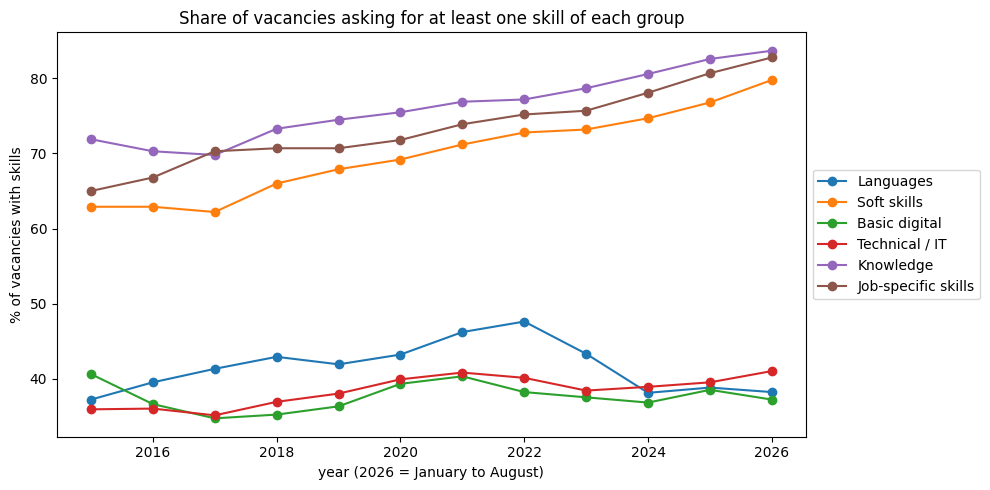

In [12]:
summary = share_table(skill_categories, 'group')
summary['overrides'] = skill_categories.groupby('group')['source'].apply(lambda s: (s == 'override').sum())
display(summary)

vac = vacancies[vacancies['in_complete_period'] & vacancies['has_skills']][['vacancy_key', 'year']]
grouped = (vacancy_skills[['vacancy_key', 'skill_uri']]
           .assign(skill_uri=lambda d: d['skill_uri'].astype(str))
           .merge(skill_categories[['skill_uri', 'group']], on='skill_uri')
           .merge(vac, on='vacancy_key')
           .drop_duplicates(['vacancy_key', 'group']))
per_year = grouped.groupby(['year', 'group']).size().unstack('group')
vacancy_share = (100 * per_year.div(vac.groupby('year').size(), axis=0)).round(1)[GROUPS]
display(vacancy_share)
vacancy_share.to_csv(output_dir / 'vacancy_share_by_group_year.csv')

ax = vacancy_share.plot(figsize=(10, 5), marker='o')
ax.set_title('Share of vacancies asking for at least one skill of each group')
ax.set_ylabel('% of vacancies with skills')
ax.set_xlabel('year (2026 = January to August)')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(output_dir / 'vacancy_share_by_group_year.png', dpi=150)
plt.show()

## Results

- ESCO v1.2.1: 13,960 skills (21 duplicates dropped). Lists: 359 language, 95 transversal, 1,284 digital.
- 4,640 different skills in the data.
- Matching: 4,585 by URI (98.91% of mentions), 40 by alternative name (0.99%), 4 by preferred name, 1 ambiguous, 10 not found (0.09%). The unmatched ones are placed by the overrides.
- 55 overrides, covering 358,352 mentions. Most of them move Job-specific skills (19) and Knowledge (5) into Soft skills, and Technical / IT into Knowledge (13).
- All 5 checks PASS.

| Group | Skills | % of mentions |
|---|---|---|
| Knowledge | 1,414 | 27.4 |
| Soft skills | 102 | 25.0 |
| Job-specific skills | 2,458 | 18.9 |
| Technical / IT | 424 | 11.7 |
| Languages | 113 | 8.6 |
| Basic digital | 129 | 8.4 |

Share of vacancies asking for each group:

- Soft skills: 62.9% (2015) → 76.8% (2025), 79.8% in 2026.
- Knowledge: 71.9% → 82.6%. Job-specific skills: 65.0% → 80.7%.
- Languages: rose to a peak of 47.6% in 2022, then fell to 38.8% in 2025.
- Technical / IT: 35.9% → 39.5%. Basic digital: about the same (40.6% → 38.5%).
